# 역전파(Backpropagation) 수식 유도와 검증

**2층 신경망 (입력 2 → 은닉 2 → 출력 1)** 하나를 놓고, 손실을 줄이려면 각 가중치를 어느 쪽으로 고쳐야 하는지(기울기)를 **연쇄 법칙**으로 직접 유도합니다.

| 순서 | 하는 일 | 확인 방법 |
|---|---|---|
| 1 | 순전파 수식과 각 단계 shape | 표 |
| 2 | 역전파 6개 기울기를 출력층 → 입력층 순서로 유도 (+ 편향 b1, b2) | 수식 |
| 3 | 고정 예제를 계산기로 손계산 | 계산 과정 |
| 4 | 같은 계산을 NumPy로 | 손계산과 **소수점 4자리 일치** |
| 5 | 과제 결과 예시와 다른 곳 2군데 | 원인 재현 |
| 6 | 수치 미분(Step 4의 `numerical_gradient`)으로 기울기 재확인 | gradient check |
| 7 | ∂L/∂z2 = ŷ − y 가 왜 좋은가 (BCE vs MSE) | 그림 |
| 8 | 구한 기울기로 한 걸음 학습 → 손실이 줄어드는가 | 숫자 |

### 고정 예제

| 이름 | 값 | shape | 뜻 |
|---|---|---|---|
| x | [1, 0] | (2,) | 입력 |
| W1 | [[0.1, 0.2], [0.3, 0.4]] | (2, 2) | 1층 가중치 (행 하나 = 은닉 뉴런 하나) |
| b1 | [0, 0] | (2,) | 1층 편향 |
| W2 | [0.5, 0.6] | (2,) | 2층 가중치 |
| b2 | 0 | () | 2층 편향 |
| y (y_true) | 1 | () | 정답 |

- 활성화 함수: 두 층 모두 sigmoid σ(z) = 1 / (1 + e^(−z))
- 손실 함수: 이진 교차 엔트로피(BCE) L = −[ y·log ŷ + (1 − y)·log(1 − ŷ) ]
- **y_true = 1로 정한 이유**: 과제 원문의 "정답: y_true =" 뒤 값이 비어 있습니다. 과제의 결과 예시(ŷ = 0.6473일 때 ∂L/∂z2 = −0.3527 = ŷ − 1)가 y = 1로 계산되어 있어 1로 정했습니다.
- 기호: ŷ(와이 햇) = y_pred = 모델의 예측값, ⊙ = 같은 자리끼리 곱하기(원소별 곱), shape `()` = 숫자 하나(스칼라), log = 자연로그

## 0. 준비

Step 4에서 만든 수치 미분 함수(`src/calculus.py`)를 쓰려고 레포 최상위 폴더를 import 경로에 추가합니다. 노트북은 `notebooks/` 안에서 실행되므로 한 단계 위(`..`)가 레포 최상위입니다.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")                     # notebooks/ 의 한 단계 위 = 레포 최상위 → src 패키지를 찾을 수 있게
from src.calculus import numerical_gradient, numerical_derivative   # Step 4: 중심차분 수치 미분
from src.plot_utils import setup_korean_font, save_figure           # 한글 폰트, outputs/ 에 그림 저장

setup_korean_font()
np.set_printoptions(precision=6, suppress=True)   # 소수점 6자리까지, 1e-05 같은 지수 표기 대신 소수로

results = []                              # 검증 결과를 모아 마지막에 개수를 센다


def check(name, ok, detail=""):
    """검증 하나의 결과를 [통과]/[실패]로 출력하고 기록한다."""
    results.append(bool(ok))
    print(f"[{'통과' if ok else '실패'}] {name}  {detail}")


def fmt(value, digits=4):
    """숫자나 배열을 소수점 digits자리로 반올림해 한 줄 문자열로 만든다 (표 출력용)."""
    rounded = np.round(np.asarray(value, dtype=float), digits) + 0.0   # + 0.0: −0.0을 0.0으로 보이게
    text = np.array2string(rounded, separator=", ", floatmode="fixed", precision=digits)
    return text.replace("\n", "")

## 1. 순전파: 입력에서 손실까지

계산은 왼쪽에서 오른쪽으로 한 줄로 흘러갑니다. 대괄호 안이 그 단계에서 하는 계산이고, 아랫줄이 각 값의 shape입니다.

```
x --[W1 @ x + b1]--> z1 --[sigmoid]--> a1 --[W2 @ a1 + b2]--> z2 --[sigmoid]--> ŷ --[BCE(ŷ, y)]--> L
(2,)                 (2,)              (2,)                   ()                ()                 ()
```

$$
\begin{aligned}
z_1 &= W_1 x + b_1 \\
a_1 &= \sigma(z_1) \\
z_2 &= W_2 \cdot a_1 + b_2 \\
\hat{y} &= \sigma(z_2) \\
L &= -\left[\, y \log \hat{y} + (1-y) \log (1-\hat{y}) \,\right]
\end{aligned}
$$

| 변수 | 뜻 | shape | 그 shape이 되는 이유 |
|---|---|---|---|
| z1 | 1층 가중합 | (2,) | (2, 2) @ (2,) → (2,), 여기에 b1 (2,)을 더함 |
| a1 | 1층 출력 | (2,) | sigmoid는 원소마다 따로 적용 → shape 그대로 |
| z2 | 2층 가중합 | () | (2,)와 (2,)의 내적 → 숫자 하나, b2 ()를 더함 |
| ŷ | 예측 = 정답이 1일 확률 | () | 숫자 하나에 sigmoid |
| L | 손실 | () | 숫자 하나 |

> 과제 표기대로 W2를 shape (2,)인 벡터로 두었습니다. 교과서에 따라 W2를 (1, 2) 행렬로 두면 z2, ŷ, L이 (1,)이 되는데, 숫자는 같고 괄호만 하나 더 붙습니다.

## 2. 역전파: 연쇄 법칙으로 출력층 → 입력층 유도

### 2-0. 연쇄 법칙 한 줄 요약

톱니바퀴가 맞물려 있을 때, 첫 바퀴를 조금 돌리면 마지막 바퀴가 도는 양 = **맞물린 곳마다의 배율을 모두 곱한 값**입니다. 계산이 z → a → L로 이어져 있으면

$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} \times \frac{\partial a}{\partial z}$$

역전파는 이것을 **L에서 시작해 왼쪽으로** 한 칸씩 곱해 나가는 것입니다. 바로 오른쪽 칸의 기울기는 이미 구해 놓았으니, 각 칸에서는 **자기 칸의 배율 하나만** 새로 구해 곱하면 됩니다.

지키는 규칙 두 가지:
1. 오른쪽(L)에서 왼쪽으로 가면서, 이미 구한 기울기를 재사용한다.
2. **기울기의 shape = 그 변수의 shape.** (W1이 (2, 2)이면 ∂L/∂W1도 (2, 2)) → 유도가 맞는지 shape으로 먼저 점검할 수 있다.

### 2-1. ∂L/∂ŷ — shape ()

L = −[ y·log ŷ + (1 − y)·log(1 − ŷ) ]을 ŷ로 미분합니다. (log ŷ의 미분은 1/ŷ, log(1 − ŷ)의 미분은 −1/(1 − ŷ))

$$\frac{\partial L}{\partial \hat{y}} = -\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}}$$

y = 1이면 두 번째 항이 사라져 **−1/ŷ** 입니다. 음수라는 것은 "ŷ를 키우면 손실이 준다"는 뜻이고, ŷ가 1에 가까울수록(정답에 가까울수록) 0에 가까워집니다.

### 2-2. ∂L/∂z2 — shape () ★ 핵심

먼저 sigmoid의 미분입니다. σ(z) = (1 + e^(−z))^(−1)을 미분하면

$$\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2}
= \underbrace{\frac{1}{1+e^{-z}}}_{\sigma(z)} \cdot \underbrace{\frac{e^{-z}}{1+e^{-z}}}_{1-\sigma(z)}
= \sigma(z)\,\bigl(1-\sigma(z)\bigr)$$

그래서 ∂ŷ/∂z2 = ŷ(1 − ŷ)이고, 연쇄 법칙으로 곱하면

$$\frac{\partial L}{\partial z_2} = \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z_2}
= \left(-\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}}\right) \hat{y}(1-\hat{y})
= -y(1-\hat{y}) + (1-y)\,\hat{y}
= \hat{y} - y$$

BCE 미분의 분모 ŷ, (1 − ŷ)이 sigmoid 미분의 ŷ(1 − ŷ)과 **정확히 약분**되어 "예측 − 정답"만 남습니다. y = 1이면 (−1/ŷ) × ŷ(1 − ŷ) = −(1 − ŷ) = ŷ − 1로 바로 보입니다.

편향: z2 = W2·a1 + **b2** 이므로 ∂z2/∂b2 = 1 → **∂L/∂b2 = ∂L/∂z2**.

### 2-3. ∂L/∂W2 — shape (2,)

z2 = W2[0]·a1[0] + W2[1]·a1[1] + b2 이므로, W2[k]를 조금 늘리면 z2는 그 a1[k]배만큼 늘어납니다: ∂z2/∂W2[k] = a1[k].

$$\frac{\partial L}{\partial W_2} = \frac{\partial L}{\partial z_2} \cdot a_1$$

shape: () × (2,) → (2,). W2와 같은 shape입니다.

### 2-4. ∂L/∂a1 — shape (2,)

같은 식을 이번엔 a1[k]로 미분하면 ∂z2/∂a1[k] = W2[k]:

$$\frac{\partial L}{\partial a_1} = \frac{\partial L}{\partial z_2} \cdot W_2$$

shape: () × (2,) → (2,). W2와 a1이 곱해져 있으니 한쪽으로 미분하면 다른 쪽이 나옵니다. a1은 고칠 대상(가중치)이 아니라, **1층으로 기울기를 전달하는 통로**입니다.

### 2-5. ∂L/∂z1 — shape (2,)

a1 = σ(z1)은 원소마다 따로 계산하므로(a1[0]은 z1[0]에만 영향을 받음), 기울기도 원소마다 따로 곱합니다:

$$\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial a_1} \odot \sigma'(z_1) = \frac{\partial L}{\partial a_1} \odot a_1 (1 - a_1)$$

shape: (2,) ⊙ (2,) → (2,). 2-2와 같은 이유로 **∂L/∂b1 = ∂L/∂z1**.

### 2-6. ∂L/∂W1 — shape (2, 2)

z1[i] = W1[i, 0]·x[0] + W1[i, 1]·x[1] + b1[i] 이므로 ∂z1[i]/∂W1[i, j] = x[j]. δ = ∂L/∂z1이라 쓰면 칸 (i, j)마다

$$\frac{\partial L}{\partial W_1[i,j]} = \delta_i \cdot x_j
\quad\Longrightarrow\quad
\frac{\partial L}{\partial W_1} = \begin{bmatrix} \delta_0 x_0 & \delta_0 x_1 \\ \delta_1 x_0 & \delta_1 x_1 \end{bmatrix} = \delta \otimes x$$

(2,)와 (2,)의 **외적**(outer product, `np.outer`) → (2, 2)로 W1과 shape이 같습니다. 이 예제는 x[1] = 0이라 **두 번째 열이 0**입니다: 입력이 0인 칸의 가중치는 손실에 아무 영향을 못 주니, 고칠 이유도 없습니다.

### 2-7. 유도 정리

| 기울기 | 공식 | shape | 계산 방식 |
|---|---|---|---|
| ∂L/∂ŷ | −y/ŷ + (1 − y)/(1 − ŷ) | () | |
| ∂L/∂z2 | ∂L/∂ŷ × ŷ(1 − ŷ) = **ŷ − y** | () | 약분 |
| ∂L/∂W2 | ∂L/∂z2 · a1 | (2,) | 스칼라 × 벡터 |
| ∂L/∂b2 | ∂L/∂z2 | () | |
| ∂L/∂a1 | ∂L/∂z2 · W2 | (2,) | 스칼라 × 벡터 |
| ∂L/∂z1 | ∂L/∂a1 ⊙ a1(1 − a1) | (2,) | 원소별 곱 |
| ∂L/∂W1 | outer(∂L/∂z1, x) | (2, 2) | 외적 |
| ∂L/∂b1 | ∂L/∂z1 | (2,) | |

## 3. 손계산 (고정 예제)

계산기로 한 줄씩 계산합니다. **중간값은 소수점 6자리로 들고 가고, 마지막 비교에서만 4자리로 반올림**합니다. 중간에 4자리로 자르면 4번째 자리가 틀어질 수 있습니다 (5장에서 실제로 확인).

### 3-1. 순전파

```
z1 = W1 @ x + b1 = [0.1×1 + 0.2×0,  0.3×1 + 0.4×0] + [0, 0] = [0.1, 0.3]

a1[0] = σ(0.1) = 1 / (1 + e^-0.1) = 1 / (1 + 0.904837) = 1 / 1.904837 = 0.524979
a1[1] = σ(0.3) = 1 / (1 + e^-0.3) = 1 / (1 + 0.740818) = 1 / 1.740818 = 0.574443

z2 = W2 · a1 + b2 = 0.5 × 0.524979 + 0.6 × 0.574443 + 0
   = 0.2624895 + 0.3446658 = 0.6071553  →  0.607155

ŷ  = σ(0.607155) = 1 / (1 + e^-0.607155) = 1 / (1 + 0.544899) = 1 / 1.544899 = 0.647292

L  = −[1 × log 0.647292 + 0 × log(1 − 0.647292)] = −log 0.647292 = 0.434958
```

### 3-2. 역전파 (출력층 → 입력층)

```
∂L/∂ŷ  = −y/ŷ + (1 − y)/(1 − ŷ) = −1/ŷ                   (y = 1이라 둘째 항은 0)
       = −(1 + e^-z2) = −1.544899                         ← 1/ŷ = 1 + e^-z2 (순전파에서 계산한 값 재사용)

σ'(z2) = ŷ(1 − ŷ) = 0.647292 × 0.352708 = 0.228305
∂L/∂z2 = ∂L/∂ŷ × σ'(z2) = −1.544899 × 0.228305 = −0.352708
         검산: ŷ − y = 0.647292 − 1 = −0.352708           ← 같다 (2-2의 약분 결과)
∂L/∂b2 = ∂L/∂z2 = −0.352708

∂L/∂W2 = ∂L/∂z2 × a1 = −0.352708 × [0.524979, 0.574443] = [−0.185164, −0.202611]
∂L/∂a1 = ∂L/∂z2 × W2 = −0.352708 × [0.5, 0.6]           = [−0.176354, −0.211625]

σ'(z1) = a1 ⊙ (1 − a1) = [0.524979 × 0.475021,  0.574443 × 0.425557] = [0.249376, 0.244458]
∂L/∂z1 = ∂L/∂a1 ⊙ σ'(z1) = [−0.176354 × 0.249376,  −0.211625 × 0.244458] = [−0.043978, −0.051733]
∂L/∂b1 = ∂L/∂z1 = [−0.043978, −0.051733]

∂L/∂W1 = outer(∂L/∂z1, x) = [[−0.043978 × 1,  −0.043978 × 0],   = [[−0.043978, 0],
                              [−0.051733 × 1,  −0.051733 × 0]]      [−0.051733, 0]]
```

> 손계산은 매 줄 6자리로 반올림하므로 6번째 자리가 NumPy(반올림 없음)와 1 정도 다를 수 있습니다 (예: ∂L/∂z1 = −0.043978 vs NumPy −0.043979). 그래서 비교는 **4자리**로 합니다.

### 3-3. 손계산 결과 (4자리 반올림)

아래 셀에 손계산 결과를 4자리로 옮겨 적고, 4장에서 NumPy 결과와 비교합니다.

In [2]:
# 3장 손계산 결과를 소수점 4자리로 반올림해 옮겨 적은 값 (NumPy 결과와 비교할 기준)
hand = {
    "z1":         np.array([0.1000, 0.3000]),
    "a1":         np.array([0.5250, 0.5744]),
    "z2":         0.6072,
    "y_pred":     0.6473,
    "L":          0.4350,
    "dL/dy_pred": -1.5449,
    "dL/dz2":     -0.3527,
    "dL/dW2":     np.array([-0.1852, -0.2026]),
    "dL/db2":     -0.3527,
    "dL/da1":     np.array([-0.1764, -0.2116]),
    "dL/dz1":     np.array([-0.0440, -0.0517]),
    "dL/dW1":     np.array([[-0.0440, 0.0],
                            [-0.0517, 0.0]]),
    "dL/db1":     np.array([-0.0440, -0.0517]),
}
print(f"손계산 기록 {len(hand)}개")

손계산 기록 13개


## 4. NumPy로 같은 계산

2장에서 유도한 공식을 한 줄씩 그대로 옮깁니다. 역전파에 필요한 중간값(a1, ŷ 등)은 순전파 때 `cache`에 담아 두었다가 재사용합니다. 순전파 값을 다시 계산하지 않고 재사용하는 것이 역전파가 빠른 이유입니다.

∂L/∂z2는 일부러 약분된 결과(ŷ − y)가 아니라 **연쇄 법칙 곱(∂L/∂ŷ × ŷ(1 − ŷ))으로** 계산합니다. 그래야 "곱한 결과가 정말 ŷ − y가 되는지"를 따로 확인할 수 있습니다.

In [3]:
def sigmoid(z):
    """σ(z) = 1 / (1 + e^(−z)). 배열이면 원소마다 계산한다."""
    return 1.0 / (1.0 + np.exp(-z))


def bce(y_pred, y):
    """이진 교차 엔트로피 L = −[y·log ŷ + (1 − y)·log(1 − ŷ)]."""
    return -(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))


def forward(x, W1, b1, W2, b2, y):
    """순전파. 손실 L과, 역전파에 다시 쓸 중간값(cache)을 돌려준다."""
    z1 = W1 @ x + b1             # (2, 2) @ (2,) + (2,) → (2,)
    a1 = sigmoid(z1)             # (2,)   원소마다 sigmoid
    z2 = W2 @ a1 + b2            # (2,) @ (2,) → () 내적, 여기에 () 더하기
    y_pred = sigmoid(z2)         # ()
    L = bce(y_pred, y)           # ()
    cache = {"x": x, "W2": W2, "z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred, "y": y}
    return L, cache


def backward(cache):
    """역전파. 2장에서 유도한 공식을 출력층 → 입력층 순서로 계산한다."""
    x, W2, a1 = cache["x"], cache["W2"], cache["a1"]
    y_pred, y = cache["y_pred"], cache["y"]

    dL_dy_pred = -y / y_pred + (1 - y) / (1 - y_pred)   # 2-1  ()
    dL_dz2 = dL_dy_pred * y_pred * (1 - y_pred)         # 2-2  () × σ'(z2) = ŷ(1 − ŷ)  → ()
    dL_db2 = dL_dz2                                     #      ∂z2/∂b2 = 1  → ()
    dL_dW2 = dL_dz2 * a1                                # 2-3  () × (2,) → (2,)
    dL_da1 = dL_dz2 * W2                                # 2-4  () × (2,) → (2,)
    dL_dz1 = dL_da1 * a1 * (1 - a1)                     # 2-5  (2,) ⊙ (2,) → (2,)  원소별 곱
    dL_db1 = dL_dz1                                     #      ∂z1/∂b1 = 1  → (2,)
    dL_dW1 = np.outer(dL_dz1, x)                        # 2-6  외적 (2,) ⊗ (2,) → (2, 2)
    return {"dL/dy_pred": dL_dy_pred, "dL/dz2": dL_dz2, "dL/dW2": dL_dW2, "dL/db2": dL_db2,
            "dL/da1": dL_da1, "dL/dz1": dL_dz1, "dL/dW1": dL_dW1, "dL/db1": dL_db1}

In [4]:
# 고정 예제
x = np.array([1.0, 0.0])
W1 = np.array([[0.1, 0.2],
               [0.3, 0.4]])
b1 = np.array([0.0, 0.0])
W2 = np.array([0.5, 0.6])
b2 = 0.0
y = 1.0

L, cache = forward(x, W1, b1, W2, b2, y)
grads = backward(cache)

numpy_values = {"z1": cache["z1"], "a1": cache["a1"], "z2": cache["z2"],
                "y_pred": cache["y_pred"], "L": L, **grads}

print(f"{'name':<12}{'shape':<9}value (6자리)")
for name, value in numpy_values.items():
    print(f"{name:<12}{str(np.shape(value)):<9}{fmt(value, 6)}")

name        shape    value (6자리)
z1          (2,)     [0.100000, 0.300000]
a1          (2,)     [0.524979, 0.574443]
z2          ()       0.607155
y_pred      ()       0.647292
L           ()       0.434958
dL/dy_pred  ()       -1.544899
dL/dz2      ()       -0.352708
dL/dW2      (2,)     [-0.185165, -0.202611]
dL/db2      ()       -0.352708
dL/da1      (2,)     [-0.176354, -0.211625]
dL/dz1      (2,)     [-0.043979, -0.051734]
dL/dW1      (2, 2)   [[-0.043979,  0.000000], [-0.051734,  0.000000]]
dL/db1      (2,)     [-0.043979, -0.051734]


In [5]:
# 손계산(4자리) vs NumPy(4자리로 반올림) 비교
width = max(len(fmt(v)) for v in hand.values()) + 3          # 가장 긴 값(dL/dW1)에 칸 너비를 맞춤
print(f"{'name':<12}{'hand':<{width}}{'numpy':<{width}}same")
all_match = True
for name, hand_value in hand.items():
    numpy_rounded = np.round(np.asarray(numpy_values[name], dtype=float), 4)
    same = np.allclose(numpy_rounded, hand_value, rtol=0, atol=1e-9)   # 4자리 반올림 값이 같은가
    all_match = all_match and same
    print(f"{name:<12}{fmt(hand_value):<{width}}{fmt(numpy_rounded):<{width}}{'O' if same else 'X'}")
print()

check("손계산 = NumPy (소수점 4자리)", all_match, f"{len(hand)}개 항목")
check("∂L/∂z2 (연쇄 법칙 곱) = ŷ − y", np.isclose(grads["dL/dz2"], cache["y_pred"] - y, rtol=0, atol=1e-12),
      f"{grads['dL/dz2']:.6f} vs {cache['y_pred'] - y:.6f}")

# 규칙 2: 기울기의 shape = 그 변수의 shape
pairs = {"dL/dW1": W1, "dL/db1": b1, "dL/dW2": W2, "dL/db2": b2,
         "dL/dz1": cache["z1"], "dL/da1": cache["a1"], "dL/dz2": cache["z2"]}
shapes_ok = all(np.shape(grads[k]) == np.shape(v) for k, v in pairs.items())
check("기울기 shape = 변수 shape", shapes_ok,
      ", ".join(f"{k[3:]} {np.shape(grads[k])}" for k in pairs))

name        hand                                       numpy                                      same
z1          [0.1000, 0.3000]                           [0.1000, 0.3000]                           O
a1          [0.5250, 0.5744]                           [0.5250, 0.5744]                           O
z2          0.6072                                     0.6072                                     O
y_pred      0.6473                                     0.6473                                     O
L           0.4350                                     0.4350                                     O
dL/dy_pred  -1.5449                                    -1.5449                                    O
dL/dz2      -0.3527                                    -0.3527                                    O
dL/dW2      [-0.1852, -0.2026]                         [-0.1852, -0.2026]                         O
dL/db2      -0.3527                                    -0.3527                                   

## 5. 과제 결과 예시와 다른 곳 2군데

과제의 결과 예시는 대부분 위 결과와 같지만, 2군데가 4번째 자리에서 다릅니다. 과제도 "결과 예시는 참고용"이라고 했으므로 이 노트북은 정확한 값을 씁니다.

| 값 | 과제 예시 | 정확한 값 | 4자리 반올림 | 원인 |
|---|---|---|---|---|
| z2 | 0.6071 | 0.607155… | **0.6072** | a1을 먼저 4자리로 자른 뒤 계산하면 0.60714 → 0.6071이 나옴 (아래 코드로 재현) |
| ∂L/∂z1 두 번째 (= ∂L/∂W1[1, 0]) | −0.0513 | −0.051734… | **−0.0517** | 0.211625 × 0.244458 = 0.051734. 몇 자리로 반올림해도 0.0513은 나오지 않아 옮겨 적다 생긴 오기로 보임 |

In [6]:
# ① z2: a1을 먼저 4자리로 자르고 계산하면 과제 예시 0.6071이 재현된다
a1_rounded = np.round(cache["a1"], 4)                  # [0.5250, 0.5744]
z2_from_rounded = W2 @ a1_rounded + b2
print(f"a1을 4자리로 먼저 반올림: z2 = {z2_from_rounded:.6f} → 4자리 {z2_from_rounded:.4f}  (과제 예시)")
print(f"반올림 없이 계산        : z2 = {cache['z2']:.6f} → 4자리 {cache['z2']:.4f}  (정확한 값)")
print()

# ② ∂L/∂z1[1]: 곱하기 전 두 값을 몇 자리로 반올림해도 −0.0513은 나오지 않는다
da1_1 = grads["dL/da1"][1]                             # −0.211625…
sig_grad_1 = cache["a1"][1] * (1 - cache["a1"][1])    # σ'(z1[1]) = 0.244458…
for digits in [2, 3, 4, 5, 6]:
    product = np.round(da1_1, digits) * np.round(sig_grad_1, digits)
    print(f"{digits}자리로 반올림 후 곱: {np.round(da1_1, digits):+.{digits}f} × {np.round(sig_grad_1, digits):.{digits}f} = {product:+.4f}")

a1을 4자리로 먼저 반올림: z2 = 0.607140 → 4자리 0.6071  (과제 예시)
반올림 없이 계산        : z2 = 0.607155 → 4자리 0.6072  (정확한 값)

2자리로 반올림 후 곱: -0.21 × 0.24 = -0.0504
3자리로 반올림 후 곱: -0.212 × 0.244 = -0.0517
4자리로 반올림 후 곱: -0.2116 × 0.2445 = -0.0517
5자리로 반올림 후 곱: -0.21163 × 0.24446 = -0.0517
6자리로 반올림 후 곱: -0.211625 × 0.244458 = -0.0517


## 6. Gradient check: 수치 미분으로 한 번 더 확인

손으로 유도한 공식이 틀렸는데 NumPy 코드도 그 틀린 공식을 그대로 옮겼다면, 4장의 "일치"는 아무것도 증명하지 못합니다. 그래서 **공식을 전혀 쓰지 않는** 방법으로 한 번 더 확인합니다. Step 4에서 만든 `numerical_gradient`(중심차분)는 "가중치 하나를 h = 0.00001만큼 올렸다 내렸다 할 때 손실이 얼마나 변하나"를 직접 잽니다.

- 가중치 9개(W1 4개 + b1 2개 + W2 2개 + b2 1개)를 길이 9인 벡터 θ(세타) 하나로 펼쳐, "θ → 손실"인 함수를 만듭니다.
- `numerical_gradient`는 좌표를 하나씩 따로 움직이므로, θ의 9개 칸을 하나씩 흔들어 기울기 9개를 얻습니다.
- 비교 기준: 상대 오차 = ‖g수치 − g역전파‖ / (‖g수치‖ + ‖g역전파‖). 흔히 1e-7보다 작으면 유도가 맞다고 봅니다.

In [7]:
def pack(W1, b1, W2, b2):
    """가중치 4종을 길이 9 벡터 하나로 이어 붙인다: [W1 4개 | b1 2개 | W2 2개 | b2 1개]."""
    return np.concatenate([W1.ravel(), b1, W2, [b2]])


def unpack(theta):
    """pack의 반대: 길이 9 벡터를 W1 (2, 2), b1 (2,), W2 (2,), b2 ()로 다시 나눈다."""
    return theta[0:4].reshape(2, 2), theta[4:6], theta[6:8], theta[8]


def loss_of(theta):
    """가중치 9개(θ)만 받아 손실 하나를 돌려주는 함수 → numerical_gradient에 넘길 수 있다."""
    W1_, b1_, W2_, b2_ = unpack(theta)
    L_, _ = forward(x, W1_, b1_, W2_, b2_, y)
    return L_


theta = pack(W1, b1, W2, b2)
g_numeric = numerical_gradient(loss_of, theta)                                          # 수치 미분 (공식 안 씀)
g_backprop = pack(grads["dL/dW1"], grads["dL/db1"], grads["dL/dW2"], grads["dL/db2"])  # 역전파 (2장 공식)

labels = ["W1[0,0]", "W1[0,1]", "W1[1,0]", "W1[1,1]", "b1[0]", "b1[1]", "W2[0]", "W2[1]", "b2"]
print(f"{'param':<10}{'backprop':>13}{'numerical':>13}{'diff':>10}")
for name, gb, gn in zip(labels, g_backprop, g_numeric):
    print(f"{name:<10}{gb + 0.0:>13.8f}{gn + 0.0:>13.8f}{abs(gb - gn):>10.1e}")
print()

rel_error = np.linalg.norm(g_numeric - g_backprop) / (np.linalg.norm(g_numeric) + np.linalg.norm(g_backprop))
check("Gradient check (역전파 vs 수치 미분, 가중치 9개)", rel_error < 1e-7, f"상대 오차 {rel_error:.1e}")

param          backprop    numerical      diff
W1[0,0]     -0.04397852  -0.04397852   4.6e-12
W1[0,1]      0.00000000   0.00000000   0.0e+00
W1[1,0]     -0.05173350  -0.05173350   1.1e-11
W1[1,1]      0.00000000   0.00000000   0.0e+00
b1[0]       -0.04397852  -0.04397852   4.6e-12
b1[1]       -0.05173350  -0.05173350   1.1e-11
W2[0]       -0.18516459  -0.18516459   2.5e-13
W2[1]       -0.20261072  -0.20261072   3.3e-12
b2          -0.35270843  -0.35270843   7.2e-12

[통과] Gradient check (역전파 vs 수치 미분, 가중치 9개)  상대 오차 2.0e-11


## 7. ∂L/∂z2 = ŷ − y: 언제나 성립하나, 그리고 왜 좋은가

### 7-1. 여러 값에서 확인

2-2의 약분 결과가 이 예제만이 아니라 언제나 성립하는지, z2와 y를 바꿔 가며 수치 미분(`numerical_derivative`)과 비교합니다.

In [8]:
def loss_from_z2(z2, y):
    """z2 → ŷ = σ(z2) → BCE 손실."""
    return bce(sigmoid(z2), y)


max_diff = 0.0
for y_t in [0.0, 1.0]:
    for z2_t in [-4.0, -1.0, 0.0, 0.607155, 2.0, 5.0]:
        numeric = numerical_derivative(lambda z: loss_from_z2(z, y_t), z2_t)   # 공식 없이 잰 기울기
        formula = sigmoid(z2_t) - y_t                                          # ŷ − y
        max_diff = max(max_diff, abs(numeric - formula))
        print(f"y = {y_t:.0f}, z2 = {z2_t:+.6f}:   수치 미분 {numeric:+.6f}   ŷ − y {formula:+.6f}")
print()
check("∂L/∂z2 = ŷ − y (z2 6개 × y 2개)", max_diff < 1e-6, f"최대 차이 {max_diff:.1e}")

y = 0, z2 = -4.000000:   수치 미분 +0.017986   ŷ − y +0.017986
y = 0, z2 = -1.000000:   수치 미분 +0.268941   ŷ − y +0.268941
y = 0, z2 = +0.000000:   수치 미분 +0.500000   ŷ − y +0.500000
y = 0, z2 = +0.607155:   수치 미분 +0.647292   ŷ − y +0.647292
y = 0, z2 = +2.000000:   수치 미분 +0.880797   ŷ − y +0.880797
y = 0, z2 = +5.000000:   수치 미분 +0.993307   ŷ − y +0.993307
y = 1, z2 = -4.000000:   수치 미분 -0.982014   ŷ − y -0.982014
y = 1, z2 = -1.000000:   수치 미분 -0.731059   ŷ − y -0.731059
y = 1, z2 = +0.000000:   수치 미분 -0.500000   ŷ − y -0.500000
y = 1, z2 = +0.607155:   수치 미분 -0.352708   ŷ − y -0.352708
y = 1, z2 = +2.000000:   수치 미분 -0.119203   ŷ − y -0.119203
y = 1, z2 = +5.000000:   수치 미분 -0.006693   ŷ − y -0.006693

[통과] ∂L/∂z2 = ŷ − y (z2 6개 × y 2개)  최대 차이 1.2e-10


### 7-2. 손실을 MSE로 바꾸면?

출력은 그대로 sigmoid로 두고 손실만 평균제곱오차 L = (ŷ − y)²로 바꾸면 ∂L/∂z2 = 2(ŷ − y) × ŷ(1 − ŷ)가 되어 **약분이 일어나지 않습니다.** 차이는 모델이 정답 1을 "거의 0"이라고 확신하며 틀렸을 때(z2가 큰 음수 → ŷ ≈ 0) 드러납니다.

그림 저장: outputs/backprop_bce_vs_mse.png


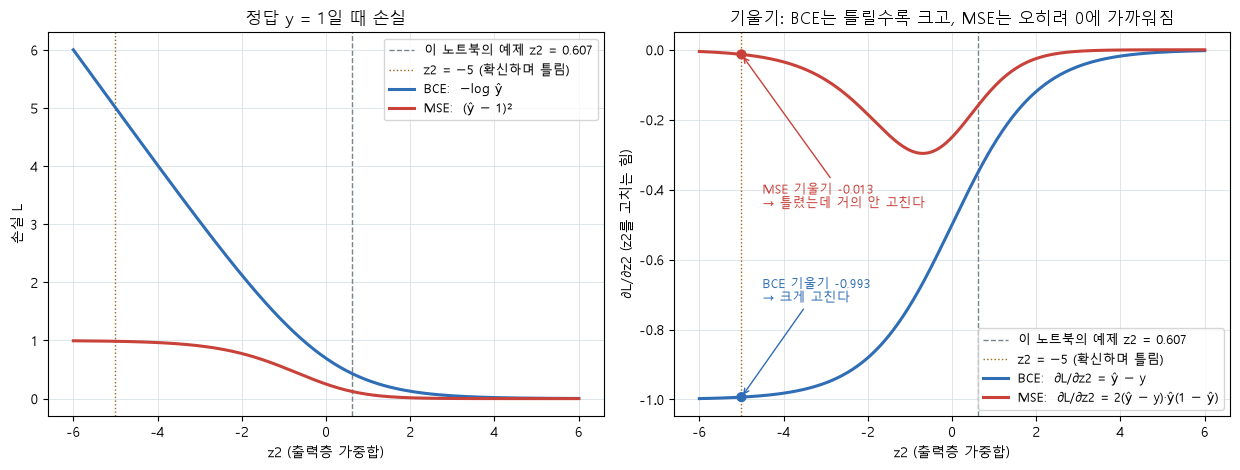

z2 = −5에서 기울기 크기: BCE 0.993, MSE 0.013 → BCE가 75배


In [9]:
z2_grid = np.linspace(-6, 6, 400)          # z2를 −6 ~ 6까지 촘촘히
y_hat_grid = sigmoid(z2_grid)
y_t = 1.0                                   # 정답이 1인 경우

loss_bce = bce(y_hat_grid, y_t)                                     # −log ŷ
loss_mse = (y_hat_grid - y_t) ** 2                                  # (ŷ − 1)²
grad_bce = y_hat_grid - y_t                                         # ŷ − y          (약분된 결과)
grad_mse = 2 * (y_hat_grid - y_t) * y_hat_grid * (1 - y_hat_grid)   # 2(ŷ − y)·ŷ(1 − ŷ)  (약분 안 됨)

z_wrong = -5.0                                                      # 정답은 1인데 ŷ ≈ 0.007: 확신하며 틀린 상태
yh_wrong = sigmoid(z_wrong)
g_bce_wrong = yh_wrong - y_t
g_mse_wrong = 2 * (yh_wrong - y_t) * yh_wrong * (1 - yh_wrong)

fig, (ax_l, ax_g) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax in (ax_l, ax_g):
    ax.axvline(cache["z2"], color="#7A858B", lw=1.0, ls="--", label=f"이 노트북의 예제 z2 = {cache['z2']:.3f}")
    ax.axvline(z_wrong, color="#9A6514", lw=1.0, ls=":", label="z2 = −5 (확신하며 틀림)")
    ax.grid(True, color="#D9E2E6", lw=0.6)
    ax.set_xlabel("z2 (출력층 가중합)")

ax_l.plot(z2_grid, loss_bce, color="#2F6DB5", lw=2.2, label="BCE:  −log ŷ")
ax_l.plot(z2_grid, loss_mse, color="#C8423A", lw=2.2, label="MSE:  (ŷ − 1)²")
ax_l.set_ylabel("손실 L")
ax_l.set_title("정답 y = 1일 때 손실")
ax_l.legend(loc="upper right", fontsize=9)

ax_g.plot(z2_grid, grad_bce, color="#2F6DB5", lw=2.2, label="BCE:  ∂L/∂z2 = ŷ − y")
ax_g.plot(z2_grid, grad_mse, color="#C8423A", lw=2.2, label="MSE:  ∂L/∂z2 = 2(ŷ − y)·ŷ(1 − ŷ)")
ax_g.scatter([z_wrong, z_wrong], [g_bce_wrong, g_mse_wrong], color=["#2F6DB5", "#C8423A"], s=40, zorder=5)
ax_g.annotate(f"BCE 기울기 {g_bce_wrong:.3f}\n→ 크게 고친다", xy=(z_wrong, g_bce_wrong), xytext=(-4.5, -0.72),
              fontsize=9, color="#2F6DB5", arrowprops=dict(arrowstyle="->", color="#2F6DB5", lw=1))
ax_g.annotate(f"MSE 기울기 {g_mse_wrong:.3f}\n→ 틀렸는데 거의 안 고친다", xy=(z_wrong, g_mse_wrong), xytext=(-4.5, -0.45),
              fontsize=9, color="#C8423A", arrowprops=dict(arrowstyle="->", color="#C8423A", lw=1))
ax_g.set_ylabel("∂L/∂z2 (z2를 고치는 힘)")
ax_g.set_title("기울기: BCE는 틀릴수록 크고, MSE는 오히려 0에 가까워짐")
ax_g.legend(loc="lower right", fontsize=9)

fig.tight_layout()
path = save_figure(fig, "backprop_bce_vs_mse.png")
print("그림 저장:", path.relative_to(path.parents[1]).as_posix())
plt.show()

print(f"z2 = −5에서 기울기 크기: BCE {abs(g_bce_wrong):.3f}, MSE {abs(g_mse_wrong):.3f} → BCE가 {g_bce_wrong / g_mse_wrong:.0f}배")

- **BCE**: 틀릴수록(ŷ가 0에 가까울수록) 기울기가 −1에 가까워져 **크게** 고치고, 맞을수록 0에 가까워져 조금 고칩니다. "틀린 만큼 고친다"는 직관과 같습니다.
- **MSE + sigmoid**: ŷ ≈ 0으로 확신하며 틀렸을 때 sigmoid가 납작한 구간이라 ŷ(1 − ŷ) ≈ 0이 곱해집니다. 그래서 **틀렸는데도 거의 고치지 않는**(학습이 멈추는) 문제가 생깁니다.
- 그래서 sigmoid 출력에는 BCE를 짝으로 씁니다. 두 손실이 각각 어떤 확률 가정에서 나오는지는 Step 7(`probability_loss.ipynb`)에서 다룹니다.

## 8. 구한 기울기로 한 걸음 학습해 보기

기울기는 "이 가중치를 조금 늘리면 손실이 얼마나 늘어나는가"입니다. 그러니 **기울기의 반대 방향**으로 조금 움직이면 손실이 줄어야 합니다.

새 가중치 = 가중치 − lr × 기울기 &nbsp;&nbsp;(lr = 학습률, 한 걸음의 크기)

Step 6의 경사하강법이 이 한 걸음을 여러 번 반복하는 것입니다.

In [10]:
lr = 0.5
W1_new = W1 - lr * grads["dL/dW1"]
b1_new = b1 - lr * grads["dL/db1"]
W2_new = W2 - lr * grads["dL/dW2"]
b2_new = b2 - lr * grads["dL/db2"]

L_new, cache_new = forward(x, W1_new, b1_new, W2_new, b2_new, y)
print("W1:", fmt(W1), "→", fmt(W1_new), "  (두 번째 열은 기울기가 0이라 그대로)")
print("W2:", fmt(W2), "→", fmt(W2_new), "  (기울기가 음수라 커짐)")
print(f"ŷ : {cache['y_pred']:.4f} → {cache_new['y_pred']:.4f}   (정답 1에 가까워짐)")
print(f"L : {L:.4f} → {L_new:.4f}")
print()
check("한 걸음 학습 후 손실 감소", L_new < L, f"{L:.4f} → {L_new:.4f}")

W1: [[0.1000, 0.2000], [0.3000, 0.4000]] → [[0.1220, 0.2000], [0.3259, 0.4000]]   (두 번째 열은 기울기가 0이라 그대로)
W2: [0.5000, 0.6000] → [0.5926, 0.7013]   (기울기가 음수라 커짐)
ŷ : 0.6473 → 0.7121   (정답 1에 가까워짐)
L : 0.4350 → 0.3395

[통과] 한 걸음 학습 후 손실 감소  0.4350 → 0.3395


## 9. 정리

| 단계 | 공식 | shape | 값 (4자리) |
|---|---|---|---|
| z1 | W1 @ x + b1 | (2,) | [0.1000, 0.3000] |
| a1 | σ(z1) | (2,) | [0.5250, 0.5744] |
| z2 | W2 · a1 + b2 | () | 0.6072 |
| ŷ | σ(z2) | () | 0.6473 |
| L | BCE | () | 0.4350 |
| ∂L/∂ŷ | −y/ŷ + (1 − y)/(1 − ŷ) | () | −1.5449 |
| ∂L/∂z2 | ŷ − y | () | −0.3527 |
| ∂L/∂W2 | ∂L/∂z2 · a1 | (2,) | [−0.1852, −0.2026] |
| ∂L/∂b2 | ∂L/∂z2 | () | −0.3527 |
| ∂L/∂a1 | ∂L/∂z2 · W2 | (2,) | [−0.1764, −0.2116] |
| ∂L/∂z1 | ∂L/∂a1 ⊙ a1(1 − a1) | (2,) | [−0.0440, −0.0517] |
| ∂L/∂W1 | outer(∂L/∂z1, x) | (2, 2) | [[−0.0440, 0], [−0.0517, 0]] |
| ∂L/∂b1 | ∂L/∂z1 | (2,) | [−0.0440, −0.0517] |

- **역전파** = 연쇄 법칙을 출력 쪽부터 적용하면서, 오른쪽에서 이미 구한 기울기를 재사용하는 것.
- sigmoid + BCE 조합에서는 약분이 일어나 **∂L/∂z2 = ŷ − y** (예측 − 정답)로 단순해지고, 틀릴수록 크게 고친다.
- 확인한 것: 손계산 = NumPy (4자리), ∂L/∂z2 = ŷ − y, 기울기 shape = 변수 shape, 역전파 = 수치 미분 (gradient check), 한 걸음 학습으로 손실 감소.

In [11]:
print(f"전체: {sum(results)}/{len(results)} 통과")

전체: 6/6 통과
